# KAN–TD-PINs: Sawtooth Burgers with Petrov–Galerkin Weak Form

**PDE:**
$$\frac{\partial u}{\partial t} + u\,\frac{\partial u}{\partial x} = \nu\,\frac{\partial^2 u}{\partial x^2}, \quad x\in[0,2\pi],\; t\in[0,T]$$

This notebook studies the 1-D viscous Burgers sawtooth benchmark using Physics-Informed Networks (PINs) in the Time-Decomposed (TD-PINs) framework with Backward Euler time discretisation.

**What this notebook does:**

- Solves the Hopf–Cole sawtooth on $[0, 2\pi]$ with $\nu = 0.07$
- Compares **STRONG** and **WEAK** (Petrov–Galerkin) loss forms on the same KAN architecture
- Analyzes Legendre projection residuals across time steps
- Visualizes KAN activations for both training regimes

The **weak form** replaces the pointwise mean-square residual with integrated projections onto a finite bank of Legendre test functions, which smooths out pointwise noise and can be more stable near sharp gradients.

In [7]:
import sys, os, time, copy
sys.path.insert(0, os.path.dirname(os.getcwd()))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pinns_framework import (
    PINArchitecture, PINSpatialDimension, PINLossFunction, PINTrainer,
    save_pinns, load_pinns, collocation_curvature,
)

torch.manual_seed(42)
np.random.seed(42)
print('torch:', torch.__version__)

torch: 2.10.0+cu128


## 1. Sawtooth Benchmark — Hopf–Cole Analytic Solution

The analytic solution on $[0, 2\pi]$ is obtained via the Hopf–Cole transform:

$$u(t, x) = 2\nu\,\partial_x \ln\phi + 4, \qquad \phi = e^{-a} + e^{-b}$$

with

$$a = \frac{(x - 4t)^2}{4\nu(t+1)}, \qquad b = \frac{(x - 4t - 2\pi)^2}{4\nu(t+1)}$$

This describes a sawtooth wave that sharpens toward a viscous shock near $x = 4t + \pi$.  With $\nu = 0.07$ the shock remains well-resolved throughout the simulation window $T = 0.02$.

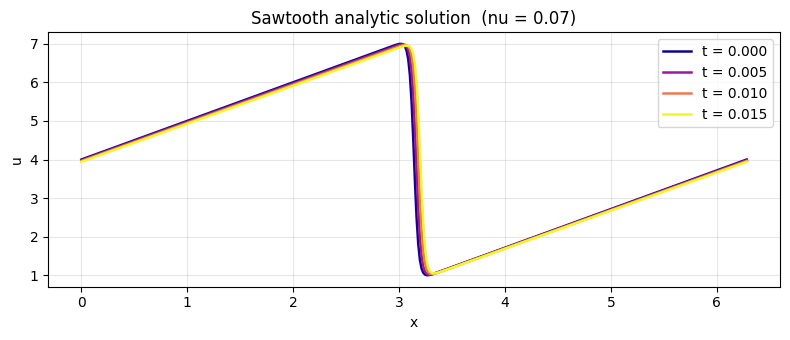

In [21]:
NU = 0.07
X0, XF = 0.0, 2 * np.pi
T_END = 0.015
DT = 0.005
NT = int(T_END / DT)   # 4 steps

def hopf_cole(t, x):
    x = np.asarray(x, dtype=float)
    c = 4 * NU * (t + 1)
    a = (-4*t + x)**2 / c
    b = (-4*t + x - 2*np.pi)**2 / c
    num = ((-8*t + 2*x) * np.exp(-a) + (-8*t + 2*x - 4*np.pi) * np.exp(-b)) / c
    den = np.exp(-b) + np.exp(-a)
    return 2 * NU * num / den + 4

x_plot = np.linspace(X0, XF, 400)
times = [k * DT for k in range(NT + 1)]

fig, ax = plt.subplots(figsize=(8, 3.5))
cmap = plt.cm.plasma
for i, t in enumerate(times):
    ax.plot(x_plot, hopf_cole(t, x_plot),
            color=cmap(i / max(len(times)-1, 1)), lw=1.8, label=f't = {t:.3f}')
ax.set_xlabel('x'); ax.set_ylabel('u')
ax.set_title('Sawtooth analytic solution  (nu = 0.07)')
ax.legend(loc='upper right'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [22]:
times

[0.0, 0.005, 0.01, 0.015]

## 2. Initial and Boundary Conditions

The initial condition is sampled from the Hopf–Cole solution at $t = 0$ on a uniform grid of 201 points.

The boundary condition is $u(t, 0) \approx u(t, 2\pi) \approx 4$ throughout the simulation window.  This is justified analytically: the exponential $e^{-b}$ with $b \sim (2\pi)^2 / (4\nu) \gg 1$ is negligible, leaving both boundary values indistinguishable from 4.

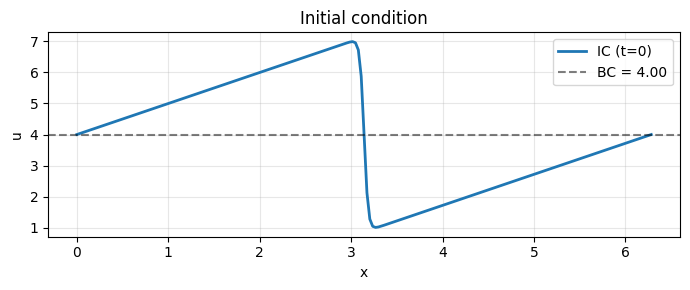

In [9]:
x_ic_np = np.linspace(X0, XF, 201)
u_ic_np = hopf_cole(0, x_ic_np)

x_ic = torch.tensor(x_ic_np, dtype=torch.float32).unsqueeze(1)
u_ic = torch.tensor(u_ic_np, dtype=torch.float32).unsqueeze(1)

u_bc_val = float(hopf_cole(0, X0))
x_bc = torch.tensor([[X0], [XF]])
u_bc = torch.full((2, 1), u_bc_val)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(x_ic_np, u_ic_np, lw=2, label='IC (t=0)')
ax.axhline(u_bc_val, color='k', ls='--', alpha=0.5, label=f'BC = {u_bc_val:.2f}')
ax.set_xlabel('x'); ax.set_ylabel('u'); ax.set_title('Initial condition')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. KAN Architecture and PDE Residual

**Architecture:** `KAN (1, 16, 1)` with `grid_size=5` and `spline_order=3`.  This gives 32 learnable B-spline activation functions (16 on the input-to-hidden edges, 16 on the hidden-to-output edges), which is expressive enough to capture the sawtooth but compact enough to visualize.

**Spatial dimension:** 200 collocation points drawn adaptively by `collocation_curvature`, which concentrates half the points where $|\partial^2 u / \partial x^2|$ is largest — useful for resolving the sharper front.

**TD-PINs Backward Euler residual:**
$$R(u; u^{n-1}, x) = \frac{u - u^{n-1}}{\Delta t} + u\,\frac{\partial u}{\partial x} - \nu\,\frac{\partial^2 u}{\partial x^2}$$

The residual function signature is **identical** for strong and weak forms; only the loss aggregation changes.

In [10]:
N_COLLOC = 500

def burgers_residual(u, u_prev, x, dt, nu):
    du_dx  = torch.autograd.grad(u.sum(),     x, create_graph=True)[0]
    du_dxx = torch.autograd.grad(du_dx.sum(), x, create_graph=True)[0]
    return (u - u_prev) / dt + u * du_dx - nu * du_dxx

x_dim = PINSpatialDimension('x', domain=(X0, XF), n_colloc=N_COLLOC)

## 4. Strong Form vs Weak Petrov–Galerkin Form

The two loss forms differ only in how the point-wise residuals $R(x_i)$ are aggregated:

$$\mathcal{L}_\text{strong} = \frac{1}{N}\sum_{i=1}^{N} R(x_i)^2$$

$$\mathcal{L}_\text{weak} = \frac{1}{K}\sum_{k=0}^{K-1} \left(\frac{1}{N}\sum_{i=1}^{N} R(x_i)\,v_k(x_i)\right)^2$$

where $v_k$ are the (column-normalised) Legendre polynomials $P_0, \ldots, P_{K-1}$ mapped from $[0, 2\pi]$ to the reference interval $[-1, 1]$.

| Property | Strong form | Weak form |
|---|---|---|
| Aggregation | Pointwise MSE | K integrated projections |
| Test functions | None (implicit delta at $x_i$) | Legendre $P_0 \ldots P_{K-1}$ |
| Sensitive to outliers | Yes | Averaged out |
| Near discontinuities | Pathological | More stable |
| K parameter | N/A | 10 (default) |

In [11]:
N_TEST = 20   # number of Legendre basis functions

loss_strong = PINLossFunction(
    [x_dim], burgers_residual, form="strong"
)
loss_weak = PINLossFunction(
    [x_dim], burgers_residual, form="weak", n_test=N_TEST
)

print(loss_strong)
print(loss_weak)
print(f'Weak form: K = {N_TEST} test functions')

PINLossFunction(form='strong', dims=['x'])
PINLossFunction(form='weak', dims=['x'], n_test=20, multi_dim_mode='total_degree')
Weak form: K = 20 test functions


## 5. Training — Strong Form Baseline

`make_trainer` builds a fresh KAN and a `PINTrainer` for a given loss function.  Both runs share the same hyperparameters so the comparison is fair.

- `epochs=4000` per time step keeps total runtime manageable on a MacBook with MPS.
- `collocation_curvature` re-samples collocation points at each epoch, concentrating effort on the steepest part of the solution.
- `ic_weight=15`, `bc_weight=5` enforce the initial and boundary data more strongly than the PDE residual during early training.

In [12]:
def make_trainer(loss_fn, label):
    net = PINArchitecture(
        'KAN', {'layers': (1, 16, 16, 16, 1), 'grid_size': 5, 'spline_order': 3}
    )
    return PINTrainer(
        net=net, scheme='TD-PINNS', loss_fn=loss_fn,
        spatial_dims=[x_dim], epochs=4000, dt=DT,
        lr=1e-2, tolerance=1e-4,
        ic_weight=15.0, bc_weight=5.0, pde_weight=1.0,
        collocation_fn=collocation_curvature,
        verbose=True, log_every=1000,
    )

print('=== Strong Form ===')
trainer_s = make_trainer(loss_strong, 'strong')
t0 = time.perf_counter()
nets_strong = trainer_s.fit(x_ic, u_ic, x_bc, u_bc, T=T_END, nu=NU)
t_strong = time.perf_counter() - t0
print(f'\nStrong form wall time: {t_strong:.1f} s')

=== Strong Form ===
checkpoint directory created: ./model
saving model version 0.0
=== TD-PINNs | step 0 — initial condition ===


  [step 0 / IC] converged at epoch 786 | loss 9.4522e-05
=== TD-PINNs | step 1/3  (t = 0.005) ===
  [step 1] epoch  1000 | loss 1.5407e+00
  [step 1] epoch  2000 | loss 1.9103e-01
  [step 1] epoch  3000 | loss 4.7597e-01
  [step 1] epoch  4000 | loss 1.0939e-01
=== TD-PINNs | step 2/3  (t = 0.01) ===
  [step 2] epoch  1000 | loss 7.9018e-01
  [step 2] epoch  2000 | loss 1.2878e-01
  [step 2] epoch  3000 | loss 2.4423e-01
  [step 2] epoch  4000 | loss 4.3122e-02
=== TD-PINNs | step 3/3  (t = 0.015) ===
  [step 3] epoch  1000 | loss 7.3281e-01
  [step 3] epoch  2000 | loss 1.7748e-01
  [step 3] epoch  3000 | loss 8.9485e-02
  [step 3] epoch  4000 | loss 4.1835e+00

Strong form wall time: 6987.0 s


## 5b. Training — Weak Petrov–Galerkin Form

Same architecture and hyperparameters; the only difference is `loss_weak` which replaces pointwise MSE with $K = 10$ Legendre projections.

In [13]:
print('=== Weak Form (Petrov-Galerkin) ===')
trainer_w = make_trainer(loss_weak, 'weak')
t0 = time.perf_counter()
nets_weak = trainer_w.fit(x_ic, u_ic, x_bc, u_bc, T=T_END, nu=NU)
t_weak = time.perf_counter() - t0
print(f'\nWeak form wall time: {t_weak:.1f} s')
print(f'Time ratio  (weak/strong): {t_weak/t_strong:.2f}x')

=== Weak Form (Petrov-Galerkin) ===
checkpoint directory created: ./model
saving model version 0.0
=== TD-PINNs | step 0 — initial condition ===


  [step 0 / IC] converged at epoch 770 | loss 9.6532e-05
=== TD-PINNs | step 1/3  (t = 0.005) ===
  [step 1] epoch  1000 | loss 1.8394e-03
  [step 1] epoch  2000 | loss 2.9581e-03
  [step 1] converged at epoch 2757 | loss 9.6442e-05
=== TD-PINNs | step 2/3  (t = 0.01) ===
  [step 2] epoch  1000 | loss 4.1960e-03
  [step 2] converged at epoch 1296 | loss 9.8763e-05
=== TD-PINNs | step 3/3  (t = 0.015) ===
  [step 3] epoch  1000 | loss 1.8956e-03
  [step 3] epoch  2000 | loss 2.3400e-04
  [step 3] converged at epoch 2094 | loss 7.9129e-05

Weak form wall time: 3722.1 s
Time ratio  (weak/strong): 0.53x


## 6. Solution Comparison

Both trained solution sequences are evaluated on a dense uniform grid of 300 points and plotted against the exact Hopf–Cole solution at each of the $N_T + 1$ time levels.

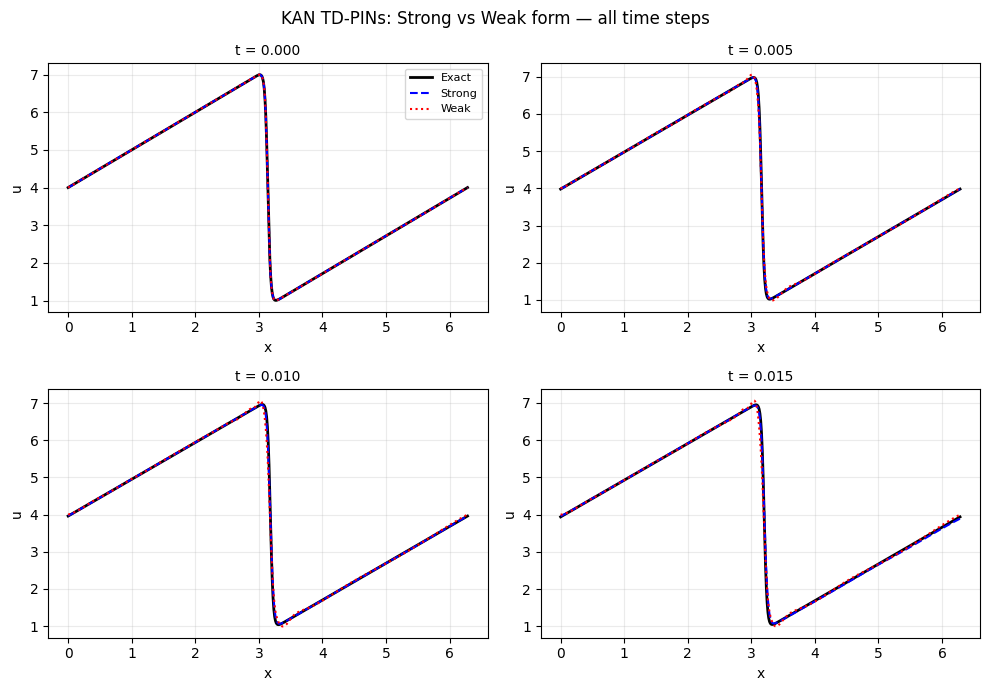

In [29]:
dev = trainer_s.device
x_eval_np = np.linspace(X0, XF, 500)
x_eval = torch.tensor(x_eval_np, dtype=torch.float32).unsqueeze(1).to(dev)

sols_strong = {}
sols_weak   = {}
for k, (ns, nw) in enumerate(zip(nets_strong, nets_weak)):
    t = times[k]
    ns.eval(); nw.eval()
    with torch.no_grad():
        sols_strong[t] = ns(x_eval).cpu().numpy().ravel()
        sols_weak[t]   = nw(x_eval).cpu().numpy().ravel()

# Grid plot: one subplot per time step
ncols = 2 #min(NT + 1, 4)
nrows = 2 #(NT + 2) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
axes = axes.flatten()

for k, t in enumerate(times):
    ax = axes[k]
    u_ex = hopf_cole(t, x_eval_np)
    ax.plot(x_eval_np, u_ex,           'k-',  lw=2,   label='Exact')
    ax.plot(x_eval_np, sols_strong[t], 'b--', lw=1.5, label='Strong')
    ax.plot(x_eval_np, sols_weak[t],   'r:',  lw=1.5, label='Weak')
    ax.set_title(f't = {t:.3f}', fontsize=10)
    ax.set_xlabel('x'); ax.set_ylabel('u')
    ax.grid(alpha=0.25)
    if k == 0: ax.legend(fontsize=8)

for ax in axes[NT+1:]: ax.set_visible(False)
fig.suptitle('KAN TD-PINs: Strong vs Weak form — all time steps', fontsize=12)
plt.tight_layout(); plt.show()

## 7. Error Analysis

Errors are computed on the dense 300-point grid using the trapezoidal rule:

$$\|e\|_{L^2} = \sqrt{\int |u - u^\star|^2\,dx}, \qquad \|e\|_{L^\infty} = \max_x |u(x) - u^\star(x)|, \qquad \|e\|_{L^2,\text{rel}} = \frac{\|e\|_{L^2}}{\|u^\star\|_{L^2}}$$

=== Per-step errors ===
          strong_L2  weak_L2  strong_Linf  weak_Linf  strong_rel_L2  weak_rel_L2
t                                                                               
0.000000   0.010640 0.010902     0.044757   0.047474       0.000970     0.000994
0.005000   0.047783 0.111809     0.181099   0.360231       0.004360     0.010201
0.010000   0.080701 0.210244     0.285179   0.748411       0.007369     0.019198
0.015000   0.121686 0.228244     0.456814   0.816899       0.011120     0.020858

=== Summary (mean over all steps) ===
  L2        strong=6.5203e-02  weak=1.4030e-01  ratio=2.152
  Linf      strong=2.4196e-01  weak=4.9325e-01  ratio=2.039
  rel_L2    strong=5.9548e-03  weak=1.2813e-02  ratio=2.152


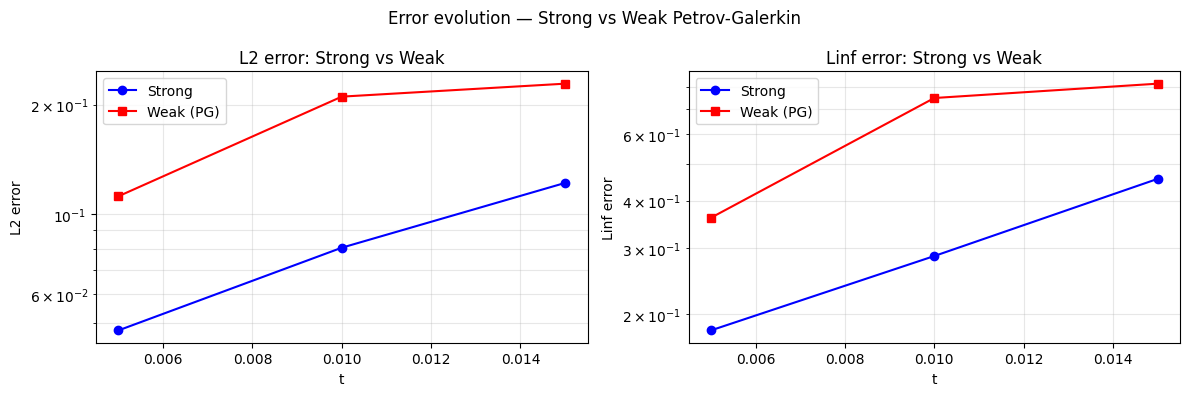

In [30]:
from pinns_framework import compute_error

rows = []
for t in times:
    u_ex = hopf_cole(t, x_eval_np)
    e_s  = compute_error(sols_strong[t], u_ex, x_eval_np)
    e_w  = compute_error(sols_weak[t],   u_ex, x_eval_np)
    rows.append({'t': t,
                 'strong_L2': e_s['L2'], 'weak_L2': e_w['L2'],
                 'strong_Linf': e_s['Linf'], 'weak_Linf': e_w['Linf'],
                 'strong_rel_L2': e_s['rel_L2'], 'weak_rel_L2': e_w['rel_L2']})

df = pd.DataFrame(rows).set_index('t')
pd.set_option('display.float_format', '{:.6f}'.format)
print('=== Per-step errors ===')
print(df.to_string())

print('\n=== Summary (mean over all steps) ===')
for col in ['L2', 'Linf', 'rel_L2']:
    s_val = df[f'strong_{col}'].mean()
    w_val = df[f'weak_{col}'].mean()
    print(f'  {col:8s}  strong={s_val:.4e}  weak={w_val:.4e}  ratio={w_val/s_val:.3f}')

# Semilogy error curves
t_plot = times[1:]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, label in [(axes[0], 'L2', 'L2'), (axes[1], 'Linf', 'Linf')]:
    ax.semilogy(t_plot, df.loc[t_plot, f'strong_{key}'], 'b-o', ms=6, label='Strong')
    ax.semilogy(t_plot, df.loc[t_plot, f'weak_{key}'],   'r-s', ms=6, label='Weak (PG)')
    ax.set_xlabel('t'); ax.set_ylabel(f'{label} error')
    ax.set_title(f'{label} error: Strong vs Weak'); ax.legend(); ax.grid(True, which='both', alpha=0.3)
plt.suptitle('Error evolution — Strong vs Weak Petrov-Galerkin', fontsize=12)
plt.tight_layout(); plt.show()

## 8. Legendre Projection Residuals

After training, we compute the $K$ Legendre projections of the final PDE residual at each time step:

$$r_k = \frac{1}{N}\sum_{i=1}^{N} R(x_i)\,P_k(x_i), \quad k = 0, \ldots, K-1$$

Ideally every $|r_k|$ should be near zero.

- For the **strong form**, only the mean-square $\sum_i R(x_i)^2$ is minimised; individual projections $r_k$ are not directly controlled and may vary.
- For the **weak form**, each projection $r_k$ is directly minimised during training, so we expect the heatmap to be uniformly darker.

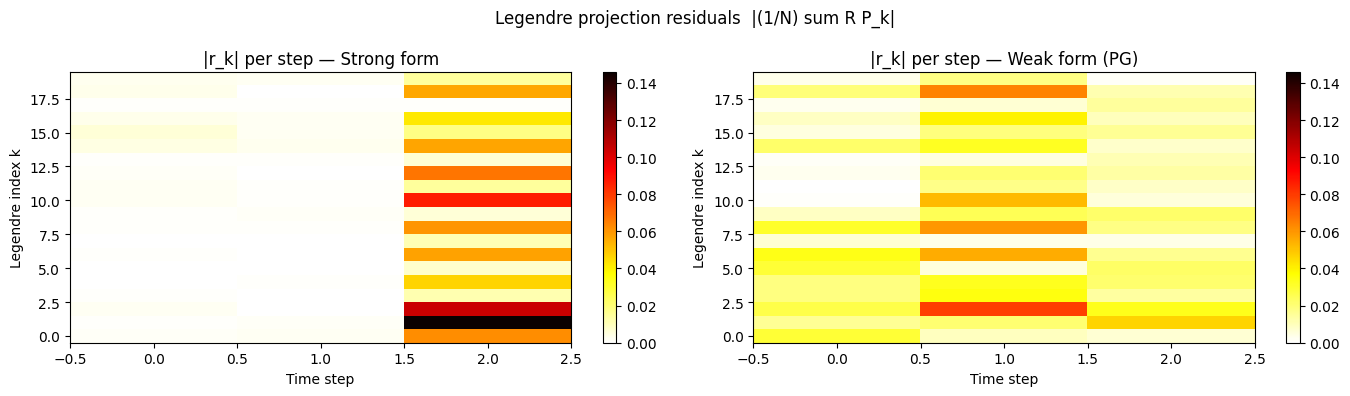

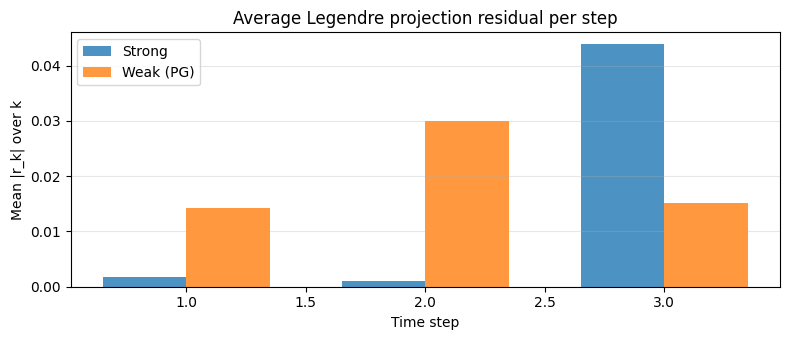

In [31]:
from pinns_framework.loss import _build_test_matrix

N_PROJ = 300
x_proj_cpu = torch.tensor(
    np.linspace(X0, XF, N_PROJ), dtype=torch.float32
).unsqueeze(1)

def compute_projections(nets, times, n_test=N_TEST):
    """
    Compute |r_k| = |(1/N) sum_i R(x_i) P_k(x_i)| for each step and each k.
    Returns array (n_steps, K).
    """
    dev = next(nets[1].parameters()).device   # match network device
    all_proj = []
    for step in range(1, len(nets)):
        x = x_proj_cpu.clone().to(dev).requires_grad_(True)
        net_n = nets[step]
        net_p = nets[step - 1]
        with torch.enable_grad():
            u      = net_n(x)
            u_prev = net_p(x.detach()).detach()
            R = burgers_residual(u=u, u_prev=u_prev, x=x, dt=DT, nu=NU)
        V  = _build_test_matrix(x, [x_dim], n_test)        # (N, K), detached
        rk = (R.detach() * V).mean(dim=0).cpu().numpy()    # (K,)
        all_proj.append(np.abs(rk))
    return np.array(all_proj)   # (n_steps, K)

proj_strong = compute_projections(nets_strong, times)
proj_weak   = compute_projections(nets_weak,   times)

# Heatmap: K projections x time steps
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
vmax_heat = proj_strong.max()
for ax, proj, title in [(axes[0], proj_strong, 'Strong form'),
                         (axes[1], proj_weak,   'Weak form (PG)')]:
    im = ax.imshow(proj.T, aspect='auto', origin='lower', cmap='hot_r',
                   vmin=0, vmax=vmax_heat)
    ax.set_xlabel('Time step'); ax.set_ylabel('Legendre index k')
    ax.set_title(f'|r_k| per step — {title}')
    plt.colorbar(im, ax=ax)
plt.suptitle('Legendre projection residuals  |(1/N) sum R P_k|', fontsize=12)
plt.tight_layout(); plt.show()

# Bar chart comparing mean projection error per step
fig, ax = plt.subplots(figsize=(8, 3.5))
steps = np.arange(1, NT + 1)
w = 0.35
ax.bar(steps - w/2, proj_strong.mean(axis=1), w, label='Strong', alpha=0.8)
ax.bar(steps + w/2, proj_weak.mean(axis=1),   w, label='Weak (PG)', alpha=0.8)
ax.set_xlabel('Time step'); ax.set_ylabel('Mean |r_k| over k')
ax.set_title('Average Legendre projection residual per step')
ax.legend(); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

## 9. KAN Spline Grid — Pruned Network

Each KAN is **deep-copied** (leaving the saved models untouched), then pruned with
`model.prune(node_th, edge_th)` to remove low-attribution nodes and edges.
The surviving splines are displayed one-per-subplot in a 16-column grid.

Pruning is applied only for visualization — `nets_strong` and `nets_weak` are unchanged.

saving model version 0.1
saving model version 0.1


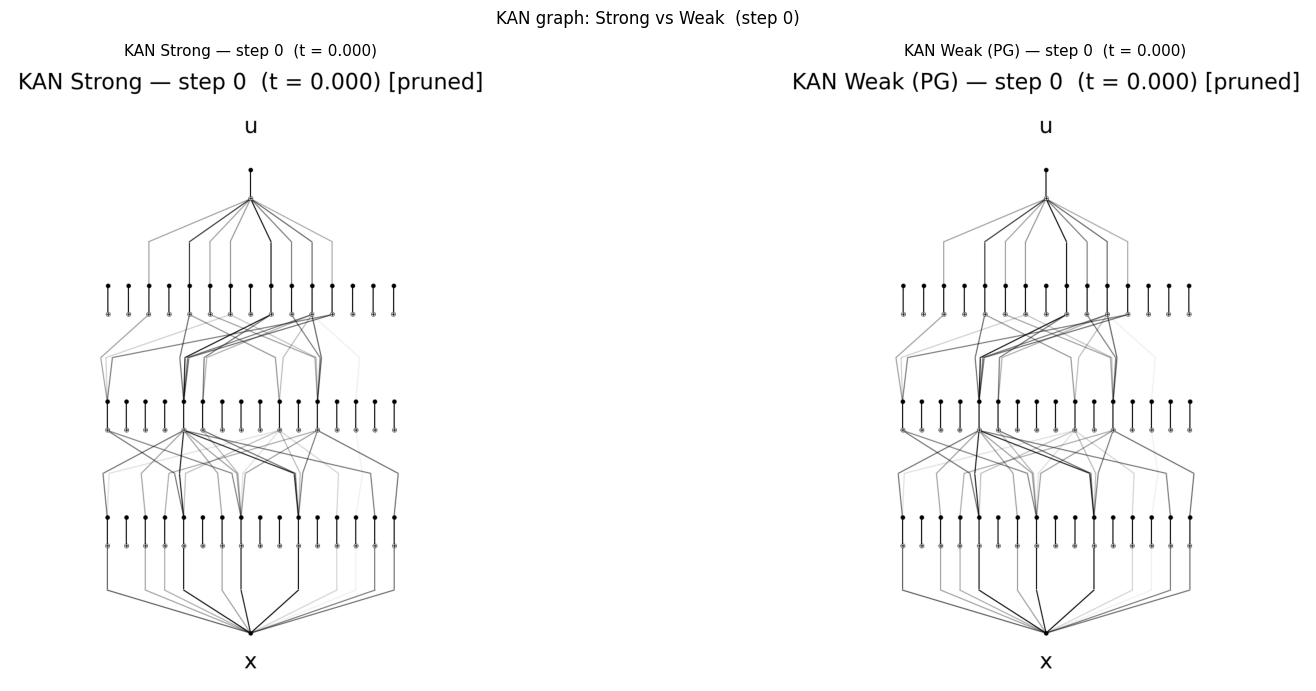

saving model version 0.1
  KAN Strong — step 0  (t = 0.000) [pruned splines]: 95 active splines after pruning
  (showing first 48 of 95)
  Saved → kan_splines_strong_step0.png


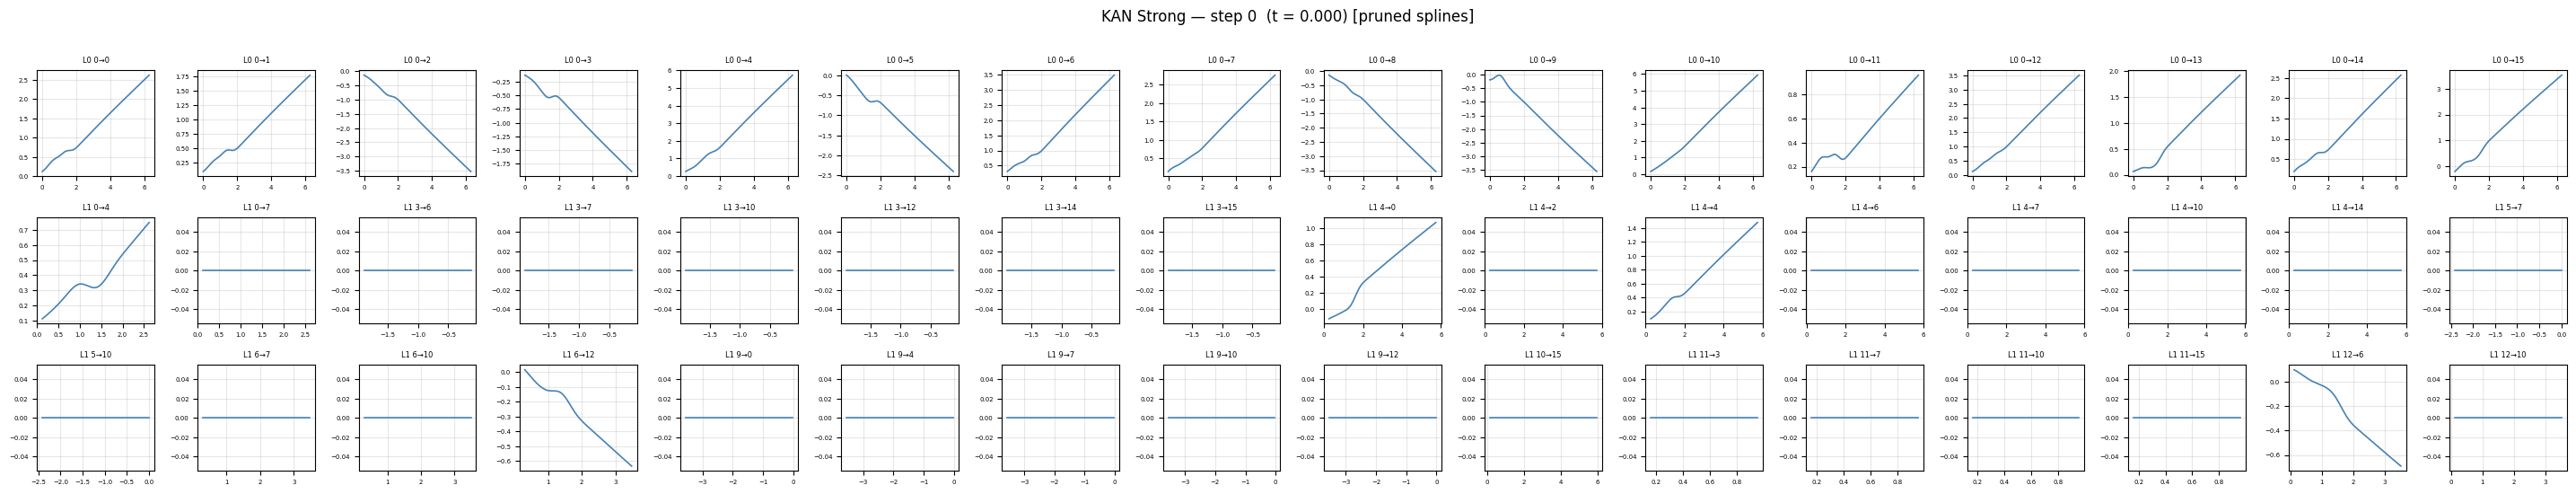

saving model version 0.1
  KAN Weak (PG) — step 0  (t = 0.000) [pruned splines]: 95 active splines after pruning
  (showing first 48 of 95)
  Saved → kan_splines_weak_pg_step0.png


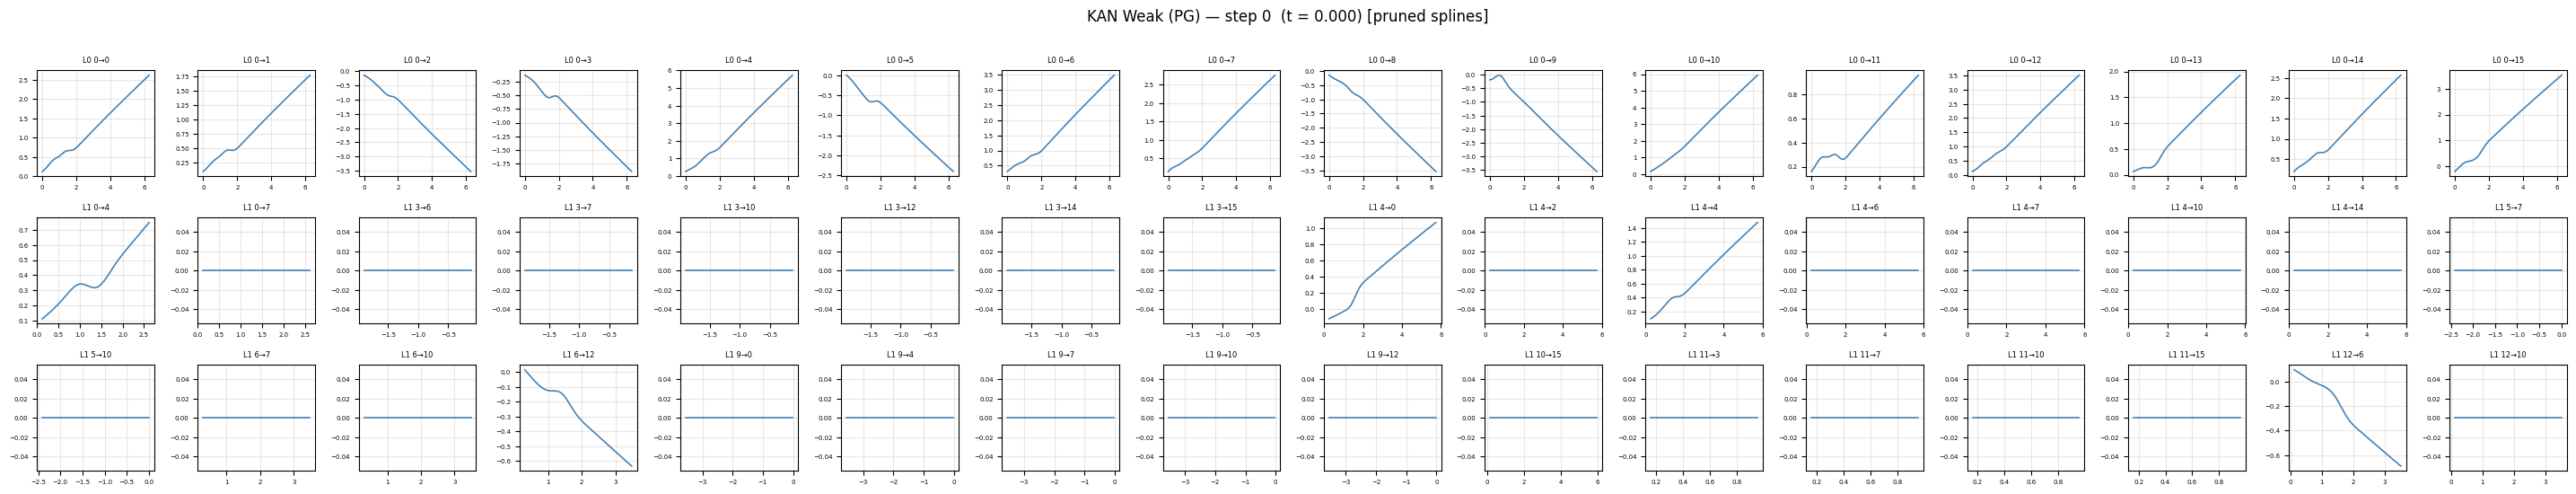

saving model version 0.1
saving model version 0.1


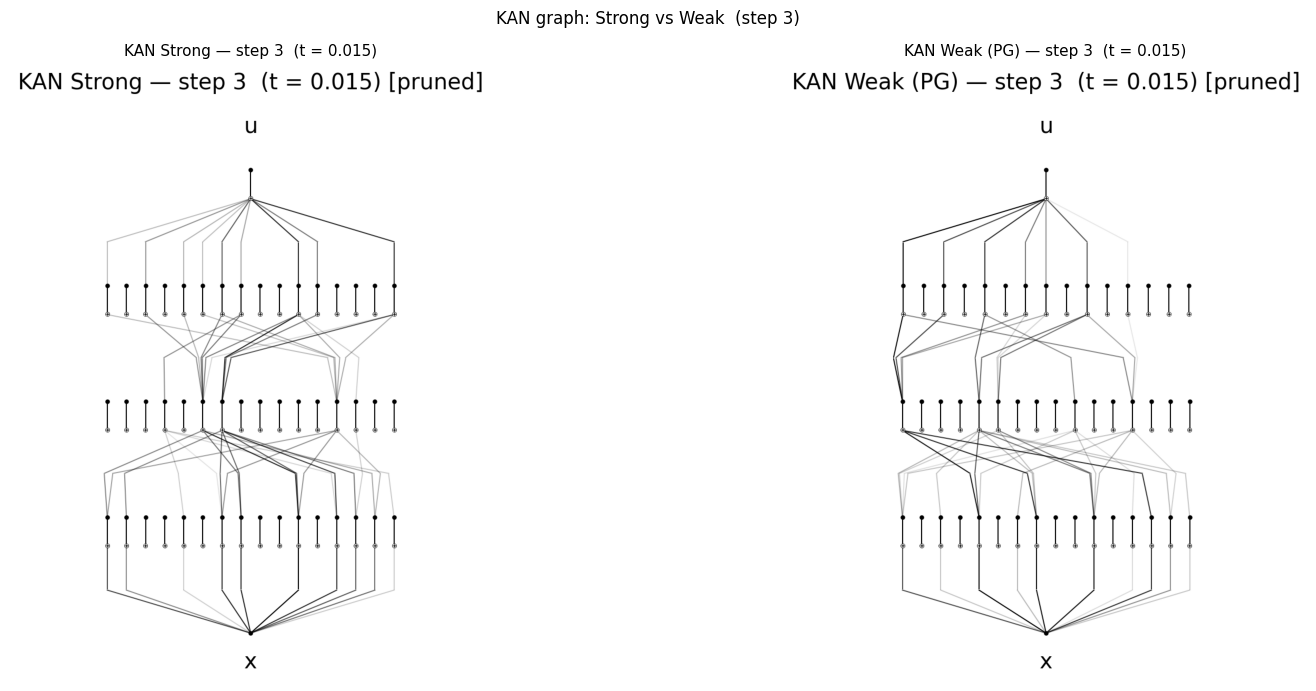

saving model version 0.1
  KAN Strong — step 3  (t = 0.015) [pruned splines]: 79 active splines after pruning
  (showing first 48 of 79)
  Saved → kan_splines_strong_step3.png


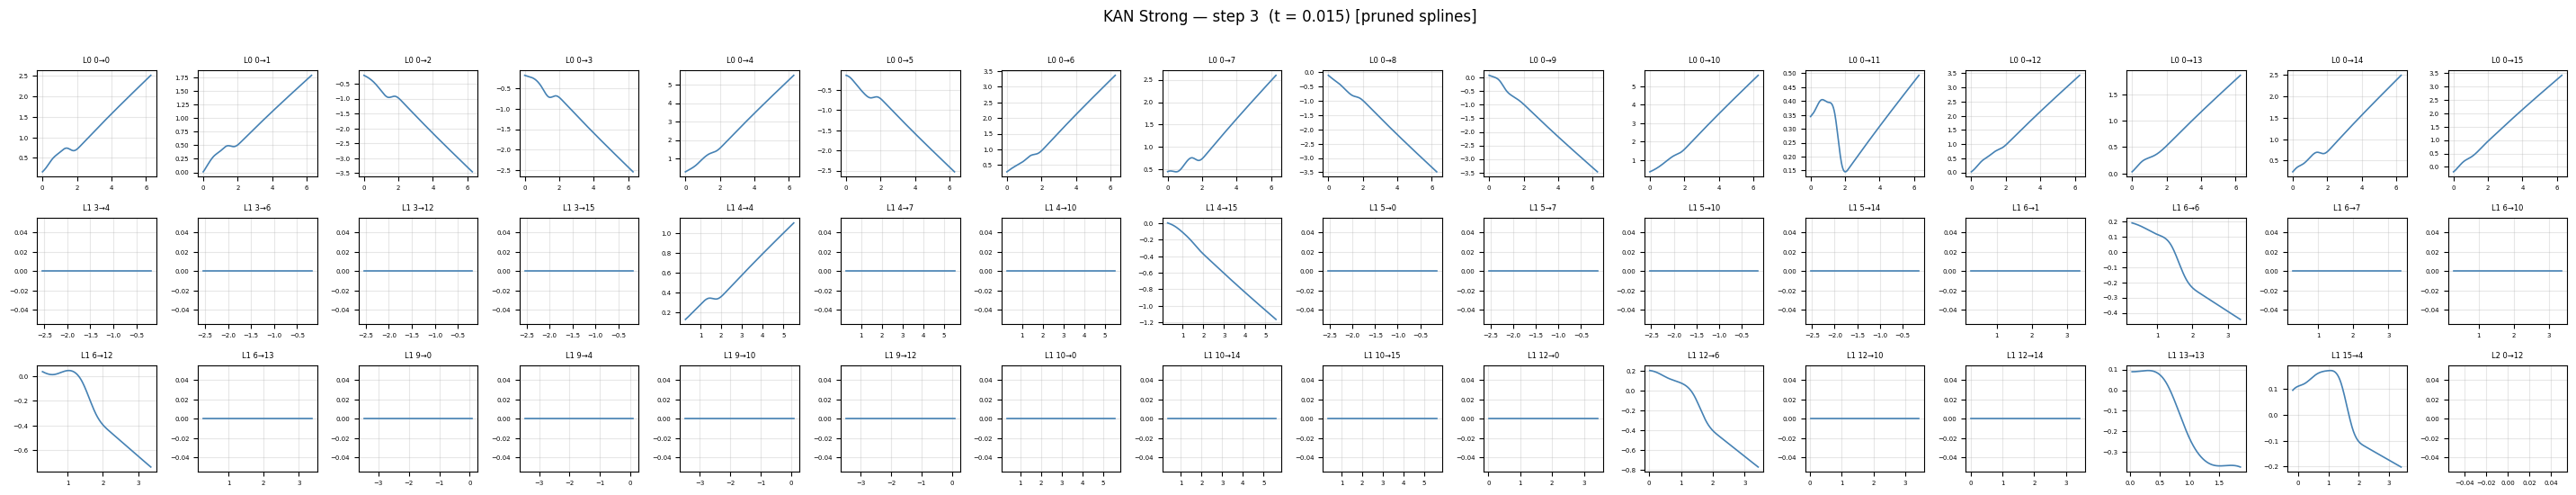

saving model version 0.1
  KAN Weak (PG) — step 3  (t = 0.015) [pruned splines]: 90 active splines after pruning
  (showing first 48 of 90)
  Saved → kan_splines_weak_pg_step3.png


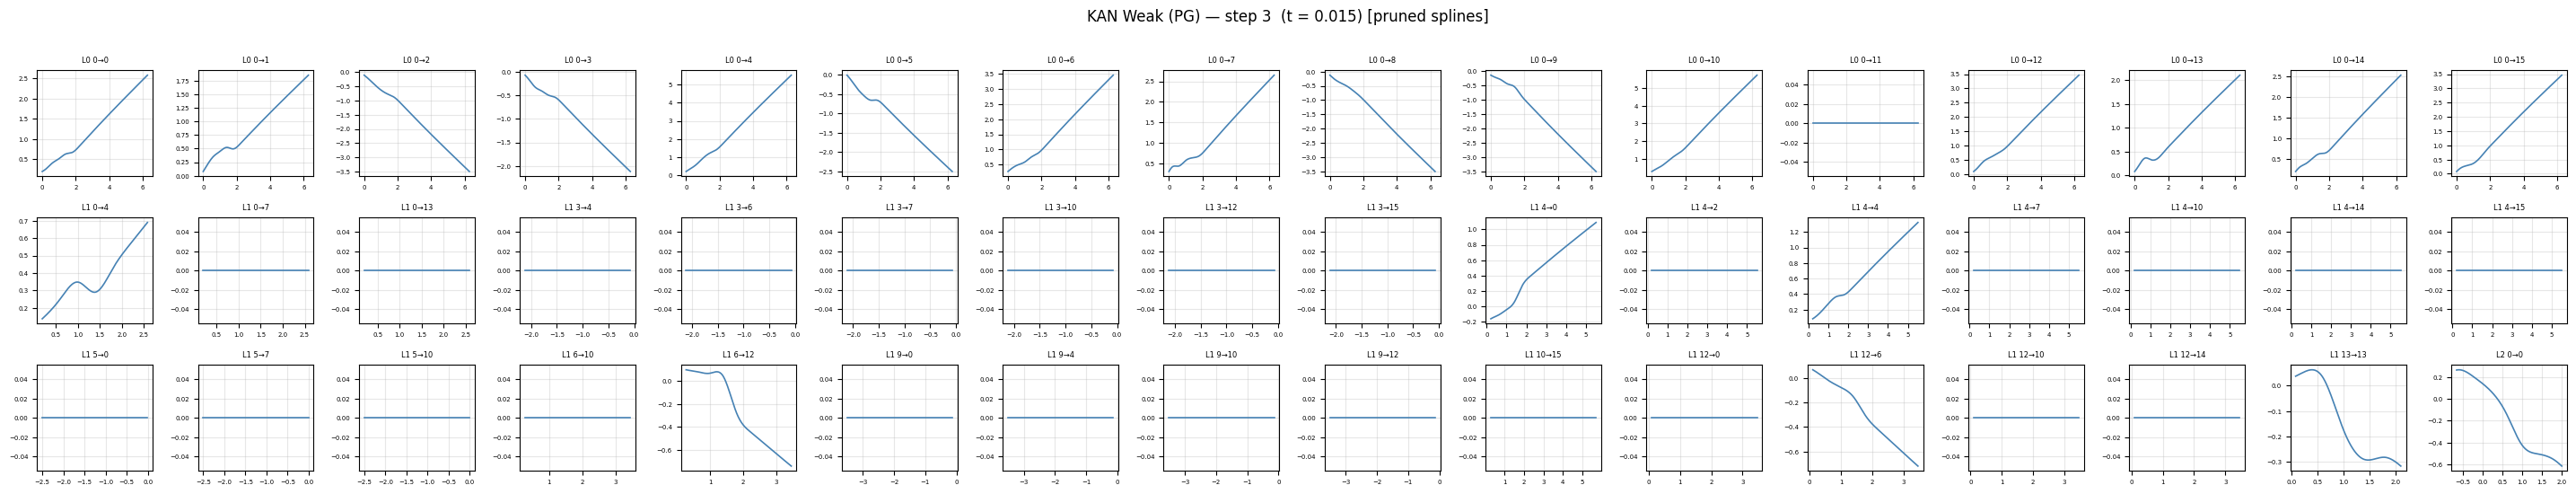

In [33]:
import io

def _kan_cpu(kan_net, x_1d):
    dev   = next(kan_net.net.parameters()).device
    x_cpu = x_1d.detach().cpu().reshape(-1, 1)
    with torch.no_grad():
        kan_net.net.eval()
        kan_net.net(x_cpu.to(dev))
    model = copy.deepcopy(kan_net.net).cpu()
    with torch.no_grad():
        model(x_cpu)
    model.get_act(x_cpu)
    return model, x_cpu


def _prune_copy(kan_net, x_1d, node_th=1e-2, edge_th=3e-2):
    """Deep-copy to CPU and prune for visualization only — original nets untouched."""
    model, x_cpu = _kan_cpu(kan_net, x_1d)
    model = model.prune(node_th=node_th, edge_th=edge_th)
    model.get_act(x_cpu)   # repopulate spline_postacts with save_act=True
    return model, x_cpu


def plot_kan_comparison(nets_s, nets_w, step, dt, n_vis=300):
    """Side-by-side KAN graph (strong vs weak) captured via BytesIO."""    
    x_vis = torch.linspace(X0, XF, n_vis).unsqueeze(1)
    imgs = []
    for nets, label in [(nets_s, 'Strong'), (nets_w, 'Weak (PG)')]:
        kan, x_cpu = _prune_copy(nets[step], x_vis)
        kan.plot(beta=3, in_vars=['x'], out_vars=['u'],
                 title=f'KAN {label} — step {step}  (t = {step * dt:.3f}) [pruned]')
        buf = io.BytesIO()
        plt.savefig(buf, format='png', bbox_inches='tight', dpi=150)
        buf.seek(0)
        imgs.append(plt.imread(buf))
        plt.close('all')

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    for ax, img, label in zip(axes, imgs, ['Strong', 'Weak (PG)']):
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f'KAN {label} — step {step}  (t = {step * dt:.3f})', fontsize=11)
    plt.suptitle(f'KAN graph: Strong vs Weak  (step {step})', fontsize=12)
    plt.tight_layout()
    plt.show()


def plot_spline_grid(model, x_cpu, title, ncols=16, nrows=3, dpi=220, save_path=None):
    """Plot every surviving spline after pruning in an ncols x nrows grid."""   
    splines = []
    for l in range(len(model.width) - 1):
        sp      = model.spline_postacts[l]          # (batch, n_out, n_in)
        n_in_a  = model.acts[l].shape[1]
        n_out_a = sp.shape[1]
        mask    = model.act_fun[l].mask.cpu()
        for i in range(n_in_a):
            for j in range(n_out_a):
                m = mask[j, i].item() if (j < mask.shape[0] and i < mask.shape[1]) else 1.0
                if m > 0:
                    rank   = torch.argsort(model.acts[l][:, i])
                    x_vals = model.acts[l][:, i][rank].detach().numpy()
                    y_vals = sp[:, j, i][rank].detach().numpy()
                    splines.append((l, i, j, x_vals, y_vals))

    n_total = len(splines)
    print(f'  {title}: {n_total} active splines after pruning')
    if n_total > nrows * ncols:
        print(f'  (showing first {nrows * ncols} of {n_total})')

    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.8, nrows * 1.8))
    axes = axes.flatten()

    for idx, (l, i, j, x_vals, y_vals) in enumerate(splines[: nrows * ncols]):
        ax = axes[idx]
        ax.plot(x_vals, y_vals, lw=1.2, color='steelblue')
        ax.set_title(f'L{l} {i}\u2192{j}', fontsize=6)
        ax.tick_params(labelsize=5)
        ax.grid(alpha=0.3)

    for idx in range(min(n_total, nrows * ncols), nrows * ncols):
        axes[idx].set_visible(False)

    fig.suptitle(title, fontsize=12, y=1.01)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=dpi, bbox_inches='tight')
        print(f'  Saved \u2192 {save_path}')
    plt.show()


x_vis = torch.linspace(X0, XF, 300).unsqueeze(1)

for step in [0, NT]:
    # 1. KAN network graph (strong vs weak side-by-side)
    plot_kan_comparison(nets_strong, nets_weak, step, DT)

    # 2. Pruned spline grid for each form
    for nets, label in [(nets_strong, 'Strong'), (nets_weak, 'Weak (PG)')]:
        slug  = label.lower().replace(' ', '_').replace('(', '').replace(')', '')
        fname = f'kan_splines_{slug}_step{step}.png'
        model, x_cpu = _prune_copy(nets[step], x_vis)
        title = f'KAN {label} — step {step}  (t = {step * DT:.3f}) [pruned splines]'
        plot_spline_grid(model, x_cpu, title, ncols=16, nrows=3, dpi=220, save_path=fname)


## 10. Conservation Diagnostics

For the viscous Burgers equation on $[0, 2\pi]$ with the given boundary conditions, the **mass** integral $M(t) = \int u\,dx$ and the **energy** integral $E(t) = \int u^2\,dx$ can be tracked over time.  Energy dissipates monotonically due to viscosity:

$$\frac{dE}{dt} = -2\nu \int \left(\frac{\partial u}{\partial x}\right)^2 dx \le 0$$

Both training regimes should respect this dissipation trend; deviations indicate training inaccuracies.

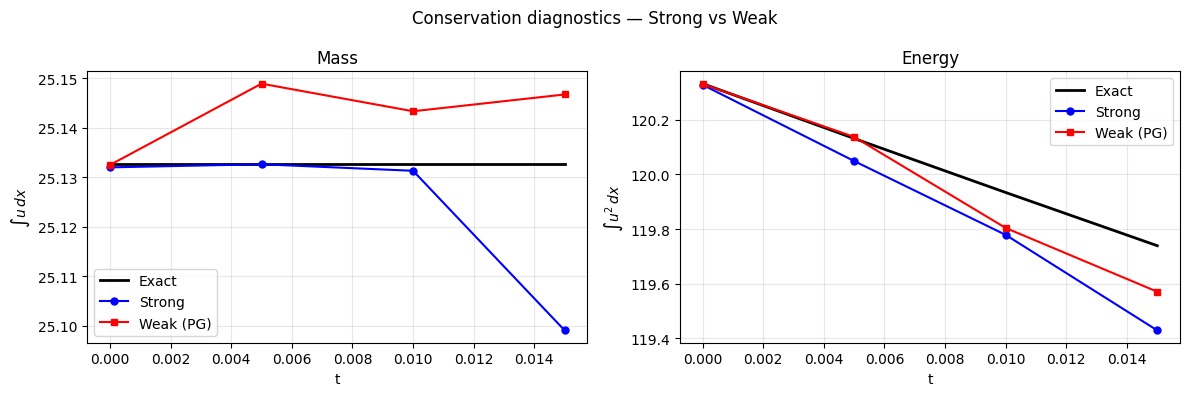

In [35]:
masses_s, masses_w, masses_ex     = [], [], []
energies_s, energies_w, energies_ex = [], [], []

for t in times:
    u_ex = hopf_cole(t, x_eval_np)
    masses_ex.append(np.trapezoid(u_ex,      x_eval_np))
    energies_ex.append(np.trapezoid(u_ex**2, x_eval_np))
    masses_s.append(np.trapezoid(sols_strong[t],      x_eval_np))
    energies_s.append(np.trapezoid(sols_strong[t]**2, x_eval_np))
    masses_w.append(np.trapezoid(sols_weak[t],        x_eval_np))
    energies_w.append(np.trapezoid(sols_weak[t]**2,   x_eval_np))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, vals_ex, vals_s, vals_w, ylabel, title in [
    (axes[0], masses_ex,   masses_s,   masses_w,   r'$\int u\,dx$',   'Mass'),
    (axes[1], energies_ex, energies_s, energies_w, r'$\int u^2\,dx$', 'Energy'),
]:
    ax.plot(times, vals_ex, 'k-',  lw=2,   label='Exact')
    ax.plot(times, vals_s,  'b-o', lw=1.5, ms=5, label='Strong')
    ax.plot(times, vals_w,  'r-s', lw=1.5, ms=5, label='Weak (PG)')
    ax.set_xlabel('t'); ax.set_ylabel(ylabel)
    ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)
plt.suptitle('Conservation diagnostics — Strong vs Weak', fontsize=12)
plt.tight_layout(); plt.show()

## 11. Summary

The table below is populated from the error DataFrame computed in Section 7.  Run the notebook end-to-end to obtain the actual values.

| Metric | Strong | Weak |
|---|---|---|
| Mean L2 error | see `df` | see `df` |
| Mean Linf error | see `df` | see `df` |
| Mean projection residual | see `proj_strong` | see `proj_weak` |
| Wall time | see `t_strong` | see `t_weak` |

**When to use each form:**

- **Strong form** is the standard choice and the correct starting point for most Physics-Informed Networks experiments.  It is computationally cheaper per training step, easier to implement, and works well when the solution is smooth and the collocation points are dense.

- **Weak (Petrov–Galerkin) form** replaces pointwise residual minimisation with integral projection onto a finite test-function basis.  It is advantageous when (a) the solution has localized sharp gradients that create high pointwise residuals at a few collocation points, (b) the collocation set is sparse or irregularly distributed, or (c) the physics naturally calls for an integral formulation (e.g., conservation laws in divergence form).  The cost per epoch is slightly higher due to the matrix-vector products with the Legendre basis, and the effective landscape is smoother, which can help or hinder convergence depending on the problem.

For the Burgers sawtooth at moderate viscosity ($\nu = 0.07$) both forms are viable.  The Legendre projection residual analysis in Section 8 provides a rigorous, form-specific diagnostic: weak-trained networks should exhibit uniformly small $|r_k|$ across all basis indices, whereas strong-trained networks may show elevated projections at higher Legendre indices.

In [36]:
ARCH        = 'KAN'
PARAMS_ARCH = {'layers': (1, 16, 16, 16, 1), 'grid_size': 5, 'spline_order': 3}

save_pinns(nets_strong, trainer_s, ARCH, PARAMS_ARCH, 'kan_sawtooth_strong.pt')
save_pinns(nets_weak,   trainer_w, ARCH, PARAMS_ARCH, 'kan_sawtooth_weak.pt')
print('Both checkpoints saved.')

Saved 4 network(s) [KAN / TD-PINNs] → 'kan_sawtooth_strong.pt'
Saved 4 network(s) [KAN / TD-PINNs] → 'kan_sawtooth_weak.pt'
Both checkpoints saved.
